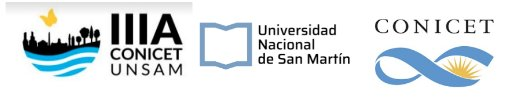  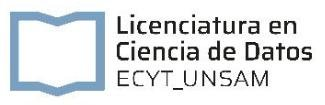

---

# NB12 — Series temporales MODIS: vegetación, temperatura y la isla de calor urbana

Lo que veremos en esta notebook:

- [x] AppEEARS: cómo descargar series temporales de MODIS para una región
- [x] Productos MOD13Q1 (NDVI/EVI, 250 m, 16 días) y MOD11A2 (LST, 1 km, 8 días)
- [x] De GeoTIFFs por fecha a cubo espaciotemporal con `xarray` + `rioxarray`
- [x] Control de calidad con la banda QA de MODIS
- [x] Descomposición STL: tendencia, estacionalidad y residuo
- [x] Test de Mann-Kendall espacial: ¿dónde hay tendencia significativa?
- [x] Isla de calor urbana: intensidad y tendencia desde 2000
- [x] Productos para la regresión espacial integradora: pendencias NDVI y LST por radio

---

> **Nota sobre saltabilidad.** Esta notebook es conceptualmente independiente del resto del curso y puede omitirse sin que la regresión integradora pierda funcionalidad: los regresores MODIS son variables opcionales en el modelo de regresión final. Si se dicta, ese modelo los absorbe y gana dos dimensiones que Sentinel-2 no puede dar (temperatura de superficie y tendencia de 25 años).

### Objetivos de la notebook

Al terminar esta clase esperamos que puedas:

- Solicitar, descargar y estructurar datos MODIS mediante AppEEARS.
- Construir un cubo espaciotemporal con `xarray` y `rioxarray`.
- Aplicar control de calidad a series de satélite con la banda QA de MODIS.
- Descomponer una serie temporal en tendencia, estacionalidad y residuo con STL.
- Aplicar el test de Mann-Kendall píxel a píxel y cartografiar las tendencias.
- Cuantificar la intensidad de la isla de calor urbana y su evolución en dos décadas.

### Datos con los que trabajaremos

El docente provee los archivos descargados con AppEEARS en `../data/raw_data/modis/`. La sección 1 documenta exactamente cómo reproducir la descarga.

- `../data/raw_data/modis/MOD13Q1/` — GeoTIFFs de MOD13Q1.061 (NDVI, EVI, QA), 2000-2025.
- `../data/raw_data/modis/MOD11A2/` — GeoTIFFs de MOD11A2.061 (LST día y noche, QA), 2000-2025.

### Conexión con el arco del curso

La detección de cambios entre 2015 y 2026 con Sentinel-2 nos dijo *cuánto* cambió la cobertura. Con MODIS tenemos ~600 imágenes desde el año 2000: podemos ver si ese cambio es el final de una tendencia larga o un evento reciente. Una de las preguntas que articulan el curso —¿existe una isla de calor en el oeste del AMBA y quiénes la sufren más?— encuentra acá su evidencia más directa: la LST es temperatura de superficie medida directamente, no un proxy espectral.

---
# 0. Bibliotecas

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import geopandas as gpd
import rasterio
from pathlib import Path
from datetime import datetime
from scipy import stats

import xarray as xr
try:
    import rioxarray as riox
    RIOXARRAY_OK = True
except ImportError:
    RIOXARRAY_OK = False
    print('rioxarray no instalado: pip install rioxarray')

from statsmodels.tsa.seasonal import STL

try:
    import pymannkendall as mk
    MK_OK = True
except ImportError:
    MK_OK = False
    print('pymannkendall no instalado: pip install pymannkendall')

from ade_tools import guardar_geotiff, estadisticas_zonales

RAW   = '../data/raw_data/'
PROC  = '../data/proc/'
OUT   = '../data/out/'

DIR_MOD13 = RAW + 'modis/MOD13Q1/'
DIR_MOD11 = RAW + 'modis/MOD11A2/'
FN_RADIOS = PROC + 'radios_con_lisa_gi.gpkg'

---
# 1. AppEEARS y los productos MODIS

## 1.1 ¿Por qué MODIS complementa a Sentinel-2?

No se trata de elegir uno: sus fortalezas son ortogonales.

| | Sentinel-2 | MODIS |
|---|---|---|
| Resolución espacial | 10 m | 250 m – 1 km |
| Revisita | 5 días | Diaria |
| Historia | 2015 – hoy | 2000 – hoy |
| Nubes / compositing | Por imagen | Composición 8/16 días |
| Uso en este curso | Clasificación de cobertura, cambio 2015→2026 | Tendencias largas, LST, isla de calor |

Sentinel-2 responde *qué cambió y dónde* con precisión milimétrica; MODIS responde *cuándo empezó el cambio y cómo evolucionó* con historia continua. La pregunta "los radios más vulnerables están perdiendo vegetación más rápido" tiene dos niveles de evidencia: la foto de dos fechas (la detección de cambios Sentinel-2) y la tendencia de 25 años (esta clase).

## 1.2 Los dos productos

**MOD13Q1.061 — NDVI/EVI, 250 m, composición de 16 días**

Cada imagen es la composición del mejor píxel en un período de 16 días: mínima nubosidad, mejor ángulo de observación. Desde febrero del 2000 hasta hoy son ~575 composiciones con una banda de calidad QA por píxel.

**MOD11A2.061 — LST día y noche, 1 km, composición de 8 días**

La temperatura de superficie (LST, *Land Surface Temperature*) es la temperatura radiométrica de la superficie medida en el infrarrojo termal. No es lo mismo que la temperatura del aire: el asfalto puede estar 15 °C más caliente que la vegetación con el mismo aire encima. Es la variable canónica para estudiar la isla de calor urbana (Voogt & Oke, 2003).

## 1.3 AppEEARS: cómo se descargaron los datos

El bloque siguiente documenta el pedido. **No está pensado para ejecutarse en clase** — el procesamiento tarda 30–90 minutos en los servidores de la NASA.

In [ ]:
# ── CÓMO REPRODUCIR LA DESCARGA ──────────────────────────────────────────────
#
# 1. Registrarse en https://appeears.earthdatacloud.nasa.gov/
#    (cuenta Earthdata gratuita, misma que para LP DAAC / Earthdata Search)
#
# 2. "Start a new request" → tipo "Area"
#    Nombre sugerido: "ADE_AMBA_oeste_MODIS_2000_2025"
#
# 3. Productos:
#    • MOD13Q1.061 → bandas: _500m_16_days_NDVI
#                             _500m_16_days_EVI
#                             _500m_16_days_VI_Quality
#      (Nota: el sufijo "_500m_" es heredado del set unificado MOD13Q1+MOD13A1
#       de AppEEARS; el dato real del MOD13Q1 está a 250 m de resolución.)
#    • MOD11A2.061 → bandas: _LST_Day_1km
#                             _LST_Night_1km
#                             _QC_Day
#                             _QC_Night
#
# 4. Región: subir zona_estudio.geojson (nuestro polígono 50×50 km)
# 5. Período: 2000-02-18 al 2025-12-31
# 6. Proyección: Geographic (EPSG:4326) — reprojectamos acá
# 7. Formato: GeoTIFF
#
# El JSON del pedido está en ../data/raw_data/modis/appeears_request.json
# Tamaño estimado: ~700 MB para los dos productos.
#
# ── Verificamos que los datos estén presentes ─────────────────────────────────
import os
n_ndvi = len(list(Path(DIR_MOD13).glob('*NDVI*.tif'))) if os.path.isdir(DIR_MOD13) else 0
n_lst  = len(list(Path(DIR_MOD11).glob('*LST_Day*.tif'))) if os.path.isdir(DIR_MOD11) else 0
print(f'Archivos NDVI (MOD13Q1): {n_ndvi}')
print(f'Archivos LST  (MOD11A2): {n_lst}')
if n_ndvi == 0 or n_lst == 0:
    raise FileNotFoundError(
        'No se encontraron archivos MODIS. '
        'Asegurate de haber descargado los datos con AppEEARS '
        'y copiado a ../data/raw_data/modis/MOD13Q1/ y /MOD11A2/')

## 1.4 Nomenclatura de los archivos AppEEARS

```
MOD13Q1.061_500m_16_days_NDVI_doy2003001_aid0001.tif
                                         └─── año + día del año (DOY)
```

El DOY (*day of year*) 001 = 1 de enero, 033 ≈ 2 de febrero, etc. Extraemos la fecha de ese campo para construir el eje temporal del cubo.

---
# 2. De GeoTIFFs a cubo de datos espaciotemporal

El paradigma clásico — un bucle sobre archivos — no expresa la naturaleza del dato, que es tridimensional: `(tiempo, y, x)`. `xarray` representa exactamente esa estructura con dimensiones nombradas y coordenadas. Permite operaciones que en rasterio requerirían decenas de líneas en una sola expresión:

```python
# Anomalía de NDVI respecto a la media 2000-2010 para cada píxel y fecha
baseline = da_ndvi.sel(time=slice('2000','2010')).mean('time')
anomalia  = da_ndvi - baseline
```

El ecosistema **Pangeo** (xarray + dask + zarr + rioxarray) es el estándar emergente para análisis de datos satelitales de largo plazo a escala continental. Esta notebook lo introduce de forma instrumental; el Apéndice orienta sobre cómo escalar.

In [ ]:
import re

def fecha_de_nombre(path_str):
    """Extrae la fecha de un nombre de archivo AppEEARS con patrón *_doyYYYYDDD_*.tif"""
    m = re.search(r'_doy(\d{7})_', path_str)
    if not m:
        raise ValueError(f'Nombre inesperado: {path_str}')
    return datetime.strptime(m.group(1), '%Y%j')

# Demo
ej = 'MOD13Q1.061_500m_16_days_NDVI_doy2003017_aid0001.tif'
print(f'Ejemplo  : {ej}')
print(f'Fecha    : {fecha_de_nombre(ej).date()}')

In [ ]:
def cargar_serie_como_xarray(directorio, patron_banda, factor_escala=1.0,
                               nodata_orig=None, nombre='banda'):
    """
    Lee todos los GeoTIFFs de una banda AppEEARS y los apila en un DataArray xarray.

    factor_escala : convierte el entero almacenado al valor físico
                    MOD13Q1 NDVI → 0.0001   |  MOD11A2 LST → 0.02 (DN×0.02 = K)
    nodata_orig   : valor de fill en los GeoTIFFs (se convierte a NaN)
    """
    archivos = sorted([a for a in Path(directorio).glob('*.tif')
                       if patron_banda in a.name])
    if not archivos:
        raise FileNotFoundError(
            f'No se encontraron archivos con "{patron_banda}" en {directorio}')

    fechas, arrays, perfil, transform, crs_ = [], [], None, None, None

    for a in archivos:
        try:
            fecha = fecha_de_nombre(a.name)
        except ValueError:
            continue
        with rasterio.open(a) as src:
            datos = src.read(1).astype(float)
            if perfil is None:
                perfil, transform, crs_ = src.profile.copy(), src.transform, src.crs
        if nodata_orig is not None:
            datos[datos == nodata_orig] = np.nan
        datos *= factor_escala
        fechas.append(fecha)
        arrays.append(datos)

    cubo = np.stack(arrays, axis=0)   # (tiempo, y, x)
    nrows, ncols = cubo.shape[1], cubo.shape[2]
    xs = np.array([transform.c + (j+0.5)*transform.a for j in range(ncols)])
    ys = np.array([transform.f + (i+0.5)*transform.e for i in range(nrows)])

    da = xr.DataArray(cubo, dims=['time','y','x'],
                      coords={'time': fechas, 'y': ys, 'x': xs},
                      name=nombre,
                      attrs={'crs': str(crs_), 'factor_escala': factor_escala})
    print(f'{nombre:20s}: {len(fechas)} fechas, '
          f'{fechas[0].date()} → {fechas[-1].date()}, '
          f'forma {cubo.shape}')
    return da, perfil

# ── Cargamos las series ───────────────────────────────────────────────────────
da_ndvi, perfil_ndvi = cargar_serie_como_xarray(
    DIR_MOD13, 'NDVI',        factor_escala=0.0001, nodata_orig=-3000, nombre='NDVI')
da_evi,  _           = cargar_serie_como_xarray(
    DIR_MOD13, 'EVI',         factor_escala=0.0001, nodata_orig=-3000, nombre='EVI')
da_lstd, perfil_lst  = cargar_serie_como_xarray(
    DIR_MOD11, 'LST_Day_1km', factor_escala=0.02,   nodata_orig=0,    nombre='LST_dia')
da_lstn, _           = cargar_serie_como_xarray(
    DIR_MOD11, 'LST_Night_1km', factor_escala=0.02, nodata_orig=0,    nombre='LST_noche')

# MOD11A2 LST: el escalado oficial es DN × 0.02 → temperatura en Kelvin.
# El check siguiente detecta automáticamente si los datos están en K (rango ~270-330)
# o si por alguna razón ya vienen en °C, y aplica la conversión a °C cuando hace falta.
if float(da_lstd.mean()) > 200:     # claramente en Kelvin
    da_lstd = da_lstd - 273.15
    da_lstn = da_lstn - 273.15
da_lstd.attrs['unidades'] = '°C'
da_lstn.attrs['unidades'] = '°C'

## 2.1 Control de calidad con la banda QA

La banda QA de MOD13Q1 usa una máscara bit a bit. Los dos bits menos significativos codifican la calidad general:

| Bits [1:0] | Significado | Acción |
|---|---|---|
| `00` | Buen dato | Usar |
| `01` | Dato marginal | Usar con precaución |
| `10` | Cubierto por nieve | Descartar |
| `11` | Cubierto por nubes | Descartar |

Enmascarar antes de cualquier análisis es **obligatorio**: un NDVI medio calculado sobre píxeles nublados es numéricamente estable pero científicamente incorrecto.

In [ ]:
da_qa, _ = cargar_serie_como_xarray(
    DIR_MOD13, 'VI_Quality', factor_escala=1.0, nodata_orig=65535, nombre='QA')

qa_bits = da_qa.values.astype(np.uint16) & 0b11
mascara_buena = (qa_bits == 0) | (qa_bits == 1)

da_ndvi_qc = da_ndvi.copy()
da_ndvi_qc.values[~mascara_buena] = np.nan

pct_ok = mascara_buena.mean() * 100
print(f'Píxeles válidos por QA (promedio sobre toda la serie): {pct_ok:.1f}%')

---
# 3. La serie temporal de NDVI: ciclo anual y tendencia

Una serie NDVI urbano-periurbana tiene tres componentes:

1. **Tendencia** — el cambio secular que buscamos.
2. **Ciclo estacional** — el ritmo anual (verdes en verano, secos en invierno). En el AMBA este ciclo tiene amplitud de ~0.1-0.2 en NDVI.
3. **Residuo** — variabilidad interanual, eventos puntuales, ruido.

Un error clásico: comparar dos fechas de distinta estación y atribuir la diferencia a cambio real. La descomposición STL evita ese error separando la estacionalidad antes de estimar la tendencia.

In [ ]:
# Serie media espacial: colapsamos y/x para visualizar la serie 1D
serie_media = da_ndvi_qc.mean(dim=['x','y'], skipna=True)
t_ndvi = pd.to_datetime(serie_media.time.values)
serie_pd = pd.Series(serie_media.values, index=t_ndvi).dropna()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(t_ndvi, serie_media.values, color='#2ca02c', lw=0.7, alpha=0.6,
        label='NDVI (16 días)')
mm = serie_pd.rolling(23, center=True, min_periods=10).mean()
ax.plot(mm.index, mm.values, color='darkgreen', lw=2.0, label='Media móvil anual')
ax.set_ylabel('NDVI')
ax.set_title('Serie temporal MODIS NDVI — AMBA oeste (2000–2025)\n'
             'Media espacial sobre la zona de estudio, calidad QA aplicada')
ax.legend()
ax.grid(alpha=0.3)
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 3.1 Descomposición STL

STL (*Seasonal-Trend decomposition using LOESS*, Cleveland et al., 1990):

$$Y_t = T_t + S_t + R_t$$

$T_t$ es la tendencia (LOESS sobre la serie desestacionalizada), $S_t$ es la componente estacional, $R_t$ es el residuo. El parámetro `period=23` fija el período estacional en 23 composiciones de 16 días ≈ 1 año. `robust=True` usa ponderaciones de Bisquare que atenúan el efecto de valores extremos en la estimación de la tendencia.

In [ ]:
serie_interp = serie_pd.interpolate(method='time')   # STL requiere serie sin NaN

stl = STL(serie_interp, period=23, seasonal=7, robust=True)
res_stl = stl.fit()

fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)
fig.set_facecolor('white')

axes[0].plot(serie_interp.index, serie_interp.values, color='#2ca02c', lw=0.8)
axes[0].set_ylabel('NDVI observado')
axes[0].set_title('Descomposición STL — NDVI MODIS (promedio espacial AMBA oeste)')

axes[1].plot(serie_interp.index, res_stl.trend, color='darkgreen', lw=1.8)
axes[1].axhline(res_stl.trend.mean(), color='gray', ls='--', alpha=0.5)
axes[1].set_ylabel('Tendencia $T_t$')

axes[2].plot(serie_interp.index, res_stl.seasonal, color='steelblue', lw=0.8, alpha=0.8)
axes[2].set_ylabel('Estacionalidad $S_t$')

axes[3].plot(serie_interp.index, res_stl.resid, color='gray', lw=0.7, alpha=0.7)
axes[3].axhline(0, color='black', lw=0.5)
axes[3].set_ylabel('Residuo $R_t$')

for ax in axes:
    ax.grid(alpha=0.2)
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Qué buscar:**
- **Tendencia**: ¿sube, baja, o tiene un punto de inflexión? Una caída a partir de ~2010-2015 coincidiría con el proceso de urbanización que detectamos con Sentinel-2.
- **Amplitud estacional**: si decrece con el tiempo, hay cada vez menos vegetación respondiendo al ciclo solar — señal de impermeabilización progresiva.
- **Residuo**: outliers pronunciados valen la pena investigar (sequías de 2008, 2012, 2022 en el AMBA).

---
# 4. Test de Mann-Kendall espacial

El test de Mann-Kendall (Mann, 1945; Kendall, 1975) detecta tendencia monótona sin asumir normalidad ni linealidad. El estadístico $S$ cuenta la diferencia entre pares concordantes y discordantes en la serie; normalizado, se contrasta contra la distribución normal.

El **estimador de Sen** (Sen, 1968) — la mediana de todas las pendientes $rac{x_j - x_i}{j-i}$ — acompaña al test como estimador robusto de la magnitud de la tendencia.

**Advertencia sobre autocorrelación.** Las series de NDVI tienen autocorrelación temporal significativa, lo que infla el estadístico de Mann-Kendall y hace que más píxeles parezcan significativos. La variante **Mann-Kendall modificado** (Hamed & Rao, 1998) corrige por esta autocorrelación. `pymannkendall` la implementa como `modified_test`. Abajo usamos `original_test` sobre el promedio anual (lo que ya reduce sustancialmente la autocorrelación), pero para un análisis publicable corresponde usar `modified_test`.

Aplicado píxel a píxel sobre el promedio anual, produce:
- **Mapa de pendientes** (Sen slope): NDVI/año por píxel.
- **Mapa de p-valores**: dónde el cambio es distinguible del ruido.

In [ ]:
if not MK_OK:
    print('pymannkendall no instalado. Instalar con: pip install pymannkendall')
else:
    # Usamos el promedio anual para reducir la autocorrelación y agilizar el cómputo
    da_anual = (da_ndvi_qc
                .assign_coords(year=('time', da_ndvi_qc.time.dt.year.values))
                .groupby('year').mean('time', skipna=True))

    nrows, ncols = da_anual.shape[1], da_anual.shape[2]
    map_slope  = np.full((nrows, ncols), np.nan)
    map_pvalue = np.full((nrows, ncols), np.nan)

    total = nrows * ncols
    print(f'Mann-Kendall sobre {nrows}×{ncols} = {total:,} píxeles '
          f'(promedio anual, {da_anual.shape[0]} años)...')

    for i in range(nrows):
        for j in range(ncols):
            px = da_anual.values[:, i, j]
            ok_ = ~np.isnan(px)
            if ok_.sum() < 10:
                continue
            try:
                r = mk.original_test(px[ok_])
                map_slope[i, j]  = r.slope
                map_pvalue[i, j] = r.p
            except Exception:
                pass

    n_sig = int((map_pvalue < 0.05).sum())
    print(f'Listo. Píxeles con tendencia significativa (p<0.05): '
          f'{n_sig:,} ({n_sig/total*100:.1f}%)')

In [ ]:
if MK_OK:
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    fig.set_facecolor('white')

    vmax = float(np.nanpercentile(np.abs(map_slope), 98))
    im0 = axes[0].imshow(map_slope, cmap='RdYlGn', vmin=-vmax, vmax=vmax,
                         origin='upper', interpolation='none')
    plt.colorbar(im0, ax=axes[0], label='Pendiente Sen (NDVI/año)')
    axes[0].set_title('Tendencia de largo plazo NDVI\n(pendiente anual Sen, 2000–2025)')
    axes[0].set_axis_off()

    # Coloreamos según dirección (p<0.05), gris los no-significativos
    mapa_sig = np.where(map_pvalue < 0.05,
                        np.where(map_slope > 0, 1, -1), 0)
    im1 = axes[1].imshow(mapa_sig, cmap='RdBu', vmin=-1.5, vmax=1.5,
                         origin='upper', interpolation='none')
    cbar = plt.colorbar(im1, ax=axes[1], ticks=[-1, 0, 1])
    cbar.ax.set_yticklabels(['Pérdida\nsignif.', 'No signif.', 'Ganancia\nsignif.'])
    axes[1].set_title('Significancia de la tendencia\n(p < 0.05, Mann-Kendall)')
    axes[1].set_axis_off()

    plt.suptitle('Tendencia MODIS NDVI — AMBA oeste (2000–2025)', fontsize=12)
    plt.tight_layout()
    plt.savefig(OUT + 'modis_tendencia_ndvi.png', dpi=150,
                bbox_inches='tight', facecolor='white')
    plt.show()
    print('Guardado: modis_tendencia_ndvi.png')

**Cómo conectar este mapa con la detección de cambios Sentinel-2.** Compará la distribución de los píxeles con tendencia descendente significativa (rojo, p < 0.05) con el mapa de ΔNDVI Sentinel-2 que construimos en la notebook anterior. Si coinciden geográficamente, la pérdida que S2 detectó entre 2015 y 2026 es el capítulo final de una tendencia que MODIS ya mostraba hace 20 años. Si la pérdida S2 está en zonas sin tendencia MODIS significativa, el cambio es abrupto y reciente — lo que tendría implicancias distintas para la política pública.

---
# 5. Temperatura de superficie y la isla de calor urbana

La isla de calor urbana (UHI) es el fenómeno por el cual las zonas urbanas tienen temperatura de superficie más alta que las áreas rurales circundantes. Sus mecanismos son bien entendidos (Oke, 1987): las superficies impermeables absorben más radiación solar y la liberan como calor sensible; la pérdida de vegetación elimina el enfriamiento por evapotranspiración; la geometría urbana reduce la ventilación.

La **intensidad de la UHI** se mide como la diferencia de LST entre zonas urbanas y rurales dentro de la misma región climática. Con MODIS podemos calcularla para cada composición de 8 días desde el año 2000.

In [ ]:
# Serie media de LST diurna y nocturna sobre el área
t_lst = pd.to_datetime(da_lstd.time.values)
lst_day_m = da_lstd.mean(dim=['x','y'], skipna=True)
lst_ngt_m = da_lstn.mean(dim=['x','y'], skipna=True)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(t_lst, lst_day_m.values, color='#d62728', lw=0.7, alpha=0.5,
        label='LST diurna (~10:30 h)')
ax.plot(t_lst, lst_ngt_m.values, color='#1f77b4', lw=0.7, alpha=0.5,
        label='LST nocturna (~22:30 h)')

for t, s, c in [(t_lst, lst_day_m.values, '#8b0000'),
                (t_lst, lst_ngt_m.values, '#00008b')]:
    mm = pd.Series(s, index=t).rolling(46, center=True, min_periods=20).mean()
    ax.plot(mm.index, mm.values, color=c, lw=2.0)

ax.set_ylabel('LST (°C)')
ax.set_title('Temperatura de superficie (MODIS MOD11A2) — AMBA oeste 2000–2025\n'
             'Media espacial, composición 8 días')
ax.legend()
ax.grid(alpha=0.3)
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [ ]:
# Intensidad UHI: LST(zona_urbana) − LST(zona_rural)
# Proxy: clasificamos los píxeles por su NDVI medio de largo plazo.
# Bajo NDVI → más urbano/impermeable; alto NDVI → más verde/rural.
ndvi_lp = da_ndvi_qc.mean('time', skipna=True)
p25 = float(np.nanpercentile(ndvi_lp.values, 25))
p75 = float(np.nanpercentile(ndvi_lp.values, 75))

# Para la comparación con LST (1km) necesitamos coarsening del NDVI (250m) a 1km
factor = max(1, round(da_ndvi_qc.shape[1] / da_lstd.shape[1]))
if factor > 1:
    ndvi_lp_1km = ndvi_lp.coarsen(y=factor, x=factor, boundary='trim').mean()
else:
    ndvi_lp_1km = ndvi_lp

p25_1k = float(np.nanpercentile(ndvi_lp_1km.values, 25))
p75_1k = float(np.nanpercentile(ndvi_lp_1km.values, 75))

lst_urb = da_lstd.where(ndvi_lp_1km < p25_1k).mean(dim=['x','y'], skipna=True)
lst_rur = da_lstd.where(ndvi_lp_1km > p75_1k).mean(dim=['x','y'], skipna=True)
uhi_int = lst_urb - lst_rur

uhi_pd = pd.Series(uhi_int.values, index=t_lst)
uhi_mm = uhi_pd.rolling(46, center=True, min_periods=20).mean()

fig, ax = plt.subplots(figsize=(14, 5))
ax.fill_between(t_lst, uhi_pd.values, alpha=0.25, color='orange')
ax.plot(t_lst, uhi_pd.values, color='orange', lw=0.7, alpha=0.6,
        label='UHI (8 días)')
ax.plot(uhi_mm.index, uhi_mm.values, color='#d62728', lw=2.5,
        label='Media móvil anual')
ax.axhline(uhi_pd.median(), color='gray', ls='--', alpha=0.6,
           label=f'Mediana = {uhi_pd.median():.2f} °C')
ax.set_ylabel('Intensidad UHI (°C)')
ax.set_title('Intensidad de la isla de calor urbana — AMBA oeste 2000–2025\n'
             '(LST píxeles de baja vegetación − LST píxeles de alta vegetación)')
ax.legend()
ax.grid(alpha=0.3)
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

if MK_OK:
    uhi_anual = uhi_pd.resample('YE').median().dropna()
    r_uhi = mk.original_test(uhi_anual.values)
    print(f'Tendencia UHI (Mann-Kendall): {r_uhi.trend}')
    print(f'Pendiente Sen: {r_uhi.slope:+.4f} °C/año   p = {r_uhi.p:.4f}')

**Interpretación.** La mediana de la intensidad UHI da la diferencia térmica típica entre la zona más urbanizada y la más verde del área de estudio — un dato directamente relevante para la pregunta sobre la isla de calor que articula esta notebook. Una tendencia positiva de la intensidad (pendiente Sen > 0 y p < 0.05) significa que la brecha térmica viene creciendo: el proceso de urbanización detectado con Sentinel-2 tiene un correlato térmico medible desde el espacio.

---
# 6. Anomalías recientes versus línea de base

Comparamos el período reciente (2020-2025) con una línea de base histórica (2000-2010). Este análisis no asume linealidad y es robusto a la elección del período: captura la acumulación de cambio sin importar si fue gradual o discontinuo.

In [ ]:
# ── NDVI anomalía ────────────────────────────────────────────────────────────
base_ndvi = da_ndvi_qc.sel(
    time=da_ndvi_qc.time.dt.year.isin(range(2000, 2011))).mean('time', skipna=True)
rec_ndvi  = da_ndvi_qc.sel(
    time=da_ndvi_qc.time.dt.year.isin(range(2020, 2026))).mean('time', skipna=True)
anom_ndvi = rec_ndvi - base_ndvi

# ── LST anomalía ─────────────────────────────────────────────────────────────
base_lst = da_lstd.sel(
    time=da_lstd.time.dt.year.isin(range(2000, 2011))).mean('time', skipna=True)
rec_lst  = da_lstd.sel(
    time=da_lstd.time.dt.year.isin(range(2020, 2026))).mean('time', skipna=True)
anom_lst = rec_lst - base_lst

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.set_facecolor('white')

vnd = float(np.nanpercentile(np.abs(anom_ndvi.values), 98))
im0 = axes[0].imshow(anom_ndvi.values, cmap='RdYlGn',
                     vmin=-vnd, vmax=vnd, origin='upper')
plt.colorbar(im0, ax=axes[0], label='ΔNDVI')
axes[0].set_title('Anomalía NDVI\n(2020-2025 − 2000-2010)', fontsize=11)
axes[0].set_axis_off()

vls = float(np.nanpercentile(np.abs(anom_lst.values), 98))
im1 = axes[1].imshow(anom_lst.values, cmap='RdBu_r',
                     vmin=-vls, vmax=vls, origin='upper')
plt.colorbar(im1, ax=axes[1], label='ΔLST (°C)')
axes[1].set_title('Anomalía LST diurna\n(2020-2025 − 2000-2010)', fontsize=11)
axes[1].set_axis_off()

plt.suptitle('Anomalías período reciente vs línea de base histórica\n'
             'MODIS NDVI 250m y LST 1km — AMBA oeste', fontsize=12)
plt.tight_layout()
plt.savefig(OUT + 'modis_anomalias.png', dpi=150,
            bbox_inches='tight', facecolor='white')
plt.show()

# Correlación espacial ΔNDVI × ΔLST
if factor > 1:
    ndvi_1km = anom_ndvi.coarsen(y=factor, x=factor, boundary='trim').mean()
else:
    ndvi_1km = anom_ndvi

xv = ndvi_1km.values.ravel()
yv = anom_lst.values.ravel()
ok_ = ~np.isnan(xv) & ~np.isnan(yv)
r, p = stats.pearsonr(xv[ok_], yv[ok_])
print(f'Correlación Pearson ΔNDVI × ΔLST: r = {r:.3f}  p = {p:.2e}')
print('(r negativo confirma: donde cae el NDVI, sube la temperatura)')

---
# 7. Productos para la regresión integradora


Exportamos los resultados de tendencia por radio censal. Son variables opcionales para el modelo de regresión espacial integradora: `lst_slope_mk_mediana` (°C/año) y `ndvi_slope_mk_mediana` (NDVI/año) por radio. Si esta notebook fue saltada, ese modelo corre igual con los regresores ya disponibles.

In [ ]:
# Guardamos los rasters de pendencias como GeoTIFF
guardar_geotiff(PROC + 'modis_slope_ndvi.tif',
                map_slope.astype(np.float32), perfil_ndvi,
                nodata=np.nan, nombres_bandas=['slope_ndvi_MK'])
print('Guardado: modis_slope_ndvi.tif')

if MK_OK:
    # Mann-Kendall sobre LST anual
    nrows_l, ncols_l = da_lstd.shape[1], da_lstd.shape[2]
    slope_lst = np.full((nrows_l, ncols_l), np.nan)

    da_lst_anual = (da_lstd
                    .assign_coords(year=('time', da_lstd.time.dt.year.values))
                    .groupby('year').mean('time', skipna=True))

    for i in range(nrows_l):
        for j in range(ncols_l):
            px = da_lst_anual.values[:, i, j]
            ok_ = ~np.isnan(px)
            if ok_.sum() < 10:
                continue
            try:
                slope_lst[i, j] = mk.original_test(px[ok_]).slope
            except Exception:
                pass

    guardar_geotiff(PROC + 'modis_slope_lst_dia.tif',
                    slope_lst.astype(np.float32), perfil_lst,
                    nodata=np.nan, nombres_bandas=['slope_lst_dia_MK'])
    print('Guardado: modis_slope_lst_dia.tif')

In [ ]:
# Estadísticas zonales por radio → una fila por radio
gdf_radios = gpd.read_file(FN_RADIOS)
with rasterio.open(PROC + 'modis_slope_ndvi.tif') as src:
    crs_r = src.crs
if gdf_radios.crs != crs_r:
    gdf_radios = gdf_radios.to_crs(crs_r)

s_ndvi = estadisticas_zonales(PROC + 'modis_slope_ndvi.tif',
                               gdf_radios, stats=('median',), banda=1)
s_ndvi.columns = ['ndvi_slope_mk_mediana']
gdf_out = gdf_radios.join(s_ndvi)

if MK_OK:
    s_lst = estadisticas_zonales(PROC + 'modis_slope_lst_dia.tif',
                                  gdf_radios, stats=('median',), banda=1)
    s_lst.columns = ['lst_slope_mk_mediana']
    gdf_out = gdf_out.join(s_lst)

gdf_out.to_file(PROC + 'radios_con_modis.gpkg', driver='GPKG')
print('Guardado: radios_con_modis.gpkg')
print()
print('Variables disponibles para la regresión integradora (opcionales):')
print('  ndvi_slope_mk_mediana  [NDVI/año]')
if MK_OK:
    print('  lst_slope_mk_mediana   [°C/año]')
print()
print('Si esta notebook fue saltada, la NB de regresión integradora detecta la')
print('ausencia del archivo y corre con los regresores ya disponibles sin cambios.')

| Producto | Resolución | Uso |
|---|---|---|
| `modis_slope_ndvi.tif` | 250 m/píxel | Visualización comparativa con la detección de cambios Sentinel-2 |
| `modis_slope_lst_dia.tif` | 1 km/píxel | Mapa de calentamiento superficial |
| `radios_con_modis.gpkg` | Por radio | Regresores opcionales en la regresión integradora |
| `modis_tendencia_ndvi.png` | — | Figura para informe |
| `modis_anomalias.png` | — | Figura para informe |

---
# Ejercicios de entrega

---

## Ejercicio 1 — Fenología antes y después de 2010

a) Dividí la serie NDVI en dos sub-períodos: 2000-2010 y 2011-2025. Para cada uno calculá el NDVI promedio por posición en el año (composición 1 a 23). Graficalos superpuestos.

b) ¿Cambia la amplitud del ciclo anual (diferencia entre el máximo veraniego y el mínimo invernal)? Una reducción sugiere que hay menos vegetación "activa" respondiendo a la radiación solar.

c) Aplicá un test de Mann-Whitney para comparar el NDVI de enero entre los dos períodos, y repitilo para julio. Interpretá en términos del proceso de urbanización.

---

## Ejercicio 2 — Isla de calor por partido

a) Usando los polígonos de los cuatro partidos (Moreno, Merlo, Gral. Rodríguez, Marcos Paz), calculá la LST diurna media por partido con `estadisticas_zonales`.

b) Graficá las cuatro series temporales en un mismo eje.

c) Aplicá Mann-Kendall para cada partido. ¿Cuál tiene tendencia de calentamiento más pronunciada? ¿Es consistente con la tasa de urbanización observada en la notebook de detección de cambios?

---

## Ejercicio 3 — Convergencia MODIS / Sentinel-2

a) Usando el mapa de pendencia Mann-Kendall del NDVI, identificá los píxeles con tendencia descendente significativa (p < 0.05 y slope < 0).

b) Calculá por radio la fracción de píxeles con tendencia MODIS descendente significativa.

c) Correlacioná esa fracción con el `delta_ndvi` Sentinel-2 (producido en la notebook de detección de cambios). ¿Las dos fuentes cuentan la misma historia?

d) Identificá radios con alta pérdida MODIS pero bajo ΔNDVI Sentinel (o viceversa) y elaborá dos hipótesis sobre la discrepancia.

---

## Ejercicio opcional — Mann-Kendall modificado y sesgo por autocorrelación

a) Para la serie NDVI media del área de estudio, comparar `mk.original_test` con `mk.modified_test` (Hamed & Rao, 1998). ¿El p-valor cambia? ¿El estadístico de tendencia?

b) Calculá la autocorrelación de lag-1 de la serie antes y después de la desestacionalización STL. ¿La autocorrelación residual es baja? Esto justifica o cuestiona el uso de `original_test` sobre promedios anuales.

*Punteros:* Cleveland et al. (1990) STL; Mann (1945); Kendall (1975); Sen (1968); Hamed & Rao (1998); Oke (1987) *Boundary Layer Climates* cap. 8; Voogt & Oke (2003) *Thermal remote sensing of urban climates*, RSE.

---
# Apéndice — Hacia el análisis de series temporales satelitales a escala

Esta notebook trabaja con datos descargados localmente. Para análisis a escala nacional o latinoamericana el flujo cambia:

**Google Earth Engine (GEE).** Toda la colección MODIS (y Sentinel-2, Landsat, etc.) está disponible en la nube. La API Python (`earthengine-api`) permite procesar sin descargar. El modelo de cómputo es MapReduce: las operaciones se definen de forma perezosa y se ejecutan en los servidores de Google. Para un análisis de tendencias sobre todo Argentina en MODIS NDVI, GEE es hoy el camino más directo.

**Pangeo / Cloud-native.** El ecosistema `stackstac` + `dask` + `zarr` permite construir cubos de Sentinel-2 directamente desde catálogos STAC en AWS (`s3://sentinel-cogs`) sin descargar los archivos: se leen solo los trozos necesarios. `coiled` o `dask-distributed` permiten escalar a clusters efímeramente.

**Descarga masiva con `earthaccess`.** El paquete `earthaccess` (NASA) unifica autenticación y descarga de cualquier producto del DAAC en pocas líneas — es la alternativa moderna al interfaz web de AppEEARS para flujos automatizados.

Referencias: Gorelick et al. (2017) *Google Earth Engine: Planetary-scale geospatial analysis for everyone*; Hoyer & Hamman (2017) *xarray: N-D labeled arrays and datasets in Python*; Abernathey et al. (2021) *Cloud-Native Repositories for Big Scientific Data*.